# Module 7 - backprop

module 6 was slow cause the numerical gradient nudges every weight one by one. this time i do the gradient with backprop, and i also build the same kind of net in keras to compare.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # tf prints a lot of junk
import warnings
warnings.filterwarnings("ignore")
import pickle
import time
from collections import OrderedDict
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
LAST_NAME = "bandar"
BACKPROP_MODEL = f"{LAST_NAME}_mnist_backprop_model.pkl"
KERAS_MODEL = f"{LAST_NAME}_mnist_keras_model.keras"
np.random.seed(42)
tf.random.set_seed(42)

## load mnist

keras already has the dataset. i scale pixels to 0-1 and flatten each 28x28 pic into 784 numbers, then one-hot the labels.

raw train (60000, 28, 28) uint8
raw test  (10000, 28, 28) uint8
train (60000, 784) test (10000, 784)


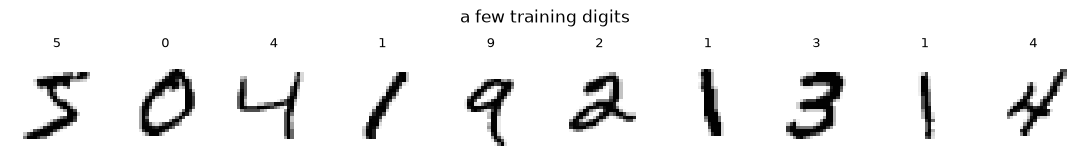

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("raw train", X_train.shape, X_train.dtype)
print("raw test ", X_test.shape, X_test.dtype)
# pixels are 0-255, scale them and flatten
x_train = X_train.reshape(-1, 784).astype(np.float32) / 255.0
x_test = X_test.reshape(-1, 784).astype(np.float32) / 255.0
y_train_oh = np.eye(10, dtype=np.float32)[y_train]
y_test_oh = np.eye(10, dtype=np.float32)[y_test]
print("train", x_train.shape, "test", x_test.shape)
fig, axes = plt.subplots(1, 10, figsize=(11, 1.6))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i], cmap=plt.cm.binary)
    ax.set_title(str(y_train[i]), fontsize=9)
    ax.axis("off")
fig.suptitle("a few training digits")
fig.tight_layout()
plt.show()

## the layers

each layer does forward, saves what it needs, then backward with the chain rule. formulas, not cleaned up:

affine
  y = xW + b
  dL/dx = dL/dy * W.T
  dL/dW = x.T * dL/dy
  dL/db = sum of dL/dy over the batch

relu: if x <= 0, output is 0 and the grad is 0 too
sigmoid: dL/dx = dL/dy * y * (1 - y)
softmax + cross entropy together: backward is just (yhat - y) / N

In [3]:
def softmax(s):
    # subtract max so exp doesnt blow up
    if s.ndim == 1:
        s = s - np.max(s)
        exp_s = np.exp(s)
        return exp_s / np.sum(exp_s)
    s = s - np.max(s, axis=1, keepdims=True)
    exp_s = np.exp(s)
    return exp_s / np.sum(exp_s, axis=1, keepdims=True)
def cross_entropy_error(y, yhat):
    if y.ndim == 1:
        y = y.reshape(1, y.size)
        yhat = yhat.reshape(1, yhat.size)
    if y.size == yhat.size:  # one hot -> class index
        y = y.argmax(axis=1)
    batch_size = yhat.shape[0]
    return -np.sum(np.log(yhat[np.arange(batch_size), y] + 1e-7)) / batch_size
class Relu:
    def __init__(self):
        self.mask = None
    def forward(self, x):
        self.mask = (x <= 0)
        out = x.copy()
        out[self.mask] = 0
        return out
    def backward(self, dout):
        dout = dout.copy()  # dont overwrite the incoming grad
        dout[self.mask] = 0
        return dout
class Sigmoid:
    def __init__(self):
        self.out = None
    def forward(self, x):
        out = 1 / (1 + np.exp(-x))
        self.out = out
        return out
    def backward(self, dout):
        return dout * (1.0 - self.out) * self.out
class Affine:
    def __init__(self, w, b):
        self.w = w
        self.b = b
        self.x = None
        self.dw = None
        self.db = None
    def forward(self, x):
        self.x = x
        return x @ self.w + self.b
    def backward(self, dout):
        dx = dout @ self.w.T
        self.dw = self.x.T @ dout
        self.db = np.sum(dout, axis=0)
        return dx
class SoftmaxWithLoss:
    def __init__(self):
        self.loss = None
        self.yhat = None
        self.y = None
    def forward(self, x, y):
        self.y = y
        self.yhat = softmax(x)
        self.loss = cross_entropy_error(self.y, self.yhat)
        return self.loss
    def backward(self, dout=1):
        batch_size = self.y.shape[0]
        if self.y.size == self.yhat.size:
            dx = (self.yhat - self.y) / batch_size
        else:
            dx = self.yhat.copy()
            dx[np.arange(batch_size), self.y] -= 1
            dx = dx / batch_size
        return dx * dout

## TwoLayerNetBackprop

affine -> relu -> affine, then softmax+loss at the end. forward() is just the layers in order. gradient() runs forward and then walks backwards for w1, b1, w2, b2.

In [4]:
class TwoLayerNetBackprop:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01, activation="relu"):
        # small random weights, biases start at 0
        self.params = {}
        self.params["w1"] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params["b1"] = np.zeros(hidden_size)
        self.params["w2"] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params["b2"] = np.zeros(output_size)
        self.layers = OrderedDict()
        self.layers["Affine1"] = Affine(self.params["w1"], self.params["b1"])
        self.layers["Activation1"] = Relu() if activation == "relu" else Sigmoid()
        self.layers["Affine2"] = Affine(self.params["w2"], self.params["b2"])
        self.last_layer = SoftmaxWithLoss()
    def forward(self, x):
        for layer in self.layers.values():
            x = layer.forward(x)
        return x
    def predict(self, x):
        return softmax(self.forward(x))
    def loss(self, x, y):
        scores = self.forward(x)
        return self.last_layer.forward(scores, y)
    def accuracy(self, x, y):
        preds = np.argmax(self.forward(x), axis=1)
        if y.ndim != 1:
            y = np.argmax(y, axis=1)
        return np.mean(preds == y)
    def numerical_gradient(self, x, y):
        # same central difference as module 6, just to check backprop
        h = 1e-4
        grad = {}
        for k in self.params.keys():
            grad[k] = np.zeros_like(self.params[k])
            it = np.nditer(self.params[k], flags=["multi_index"], op_flags=["readwrite"])
            while not it.finished:
                idx = it.multi_index
                tmp = self.params[k][idx]
                self.params[k][idx] = tmp + h
                fh1 = self.loss(x, y)
                self.params[k][idx] = tmp - h
                fh2 = self.loss(x, y)
                grad[k][idx] = (fh1 - fh2) / (2 * h)
                self.params[k][idx] = tmp  # put it back
                it.iternext()
        return grad
    def gradient(self, x, y):
        self.loss(x, y)  # forward, also stores stuff the layers need
        dout = self.last_layer.backward(1)
        layers = list(self.layers.values())
        layers.reverse()
        for layer in layers:
            dout = layer.backward(dout)
        grad = {}
        grad["w1"] = self.layers["Affine1"].dw
        grad["b1"] = self.layers["Affine1"].db
        grad["w2"] = self.layers["Affine2"].dw
        grad["b2"] = self.layers["Affine2"].db
        return grad
    backward = gradient  # same thing, just another name

## check the gradient

before training all 60000 images i compare backprop to the numerical gradient on 3 samples. they should match, backprop is just way faster.

In [5]:
check_net = TwoLayerNetBackprop(input_size=784, hidden_size=50, output_size=10)
x_batch = x_train[:3]
y_batch = y_train_oh[:3]
t0 = time.perf_counter()
grad_num = check_net.numerical_gradient(x_batch, y_batch)
num_time = time.perf_counter() - t0
t0 = time.perf_counter()
grad_bp = check_net.gradient(x_batch, y_batch)
bp_time = time.perf_counter() - t0
for k in grad_num:
    diff = np.mean(np.abs(grad_bp[k] - grad_num[k]))
    print(k, "avg abs diffrence", f"{diff:.2e}")
print(f"one step (batch 3): numerical {num_time*1000:.0f} ms, backprop {bp_time*1000:.2f} ms, about {num_time/bp_time:.0f}x faster")

w1 avg abs diffrence 5.02e-10
b1 avg abs diffrence 2.70e-09
w2 avg abs diffrence 5.79e-09
b2 avg abs diffrence 1.39e-07
one step (batch 3): numerical 4428 ms, backprop 0.24 ms, about 18261x faster


## train on mnist

784 -> 50 -> 10, batch of 100, lr 0.1, 10000 steps. with backprop this is seconds instead of half an hour.

In [6]:
bp_net = TwoLayerNetBackprop(input_size=784, hidden_size=50, output_size=10)
iters_num = 10000
batch_size = 100
lr = 0.1
steps_per_epoch = max(len(x_train) // batch_size, 1)  # 600
bp_history = {"epoch": [], "loss": [], "train_acc": [], "test_acc": []}
start_bp = time.time()
for i in range(1, iters_num + 1):
    idx = np.random.choice(len(x_train), batch_size)
    xb, yb = x_train[idx], y_train_oh[idx]
    grad = bp_net.gradient(xb, yb)
    for k in bp_net.params:
        bp_net.params[k] -= lr * grad[k]
    if i % steps_per_epoch == 0 or i == 1 or i == iters_num:
        epoch = i / steps_per_epoch
        train_loss = bp_net.loss(xb, yb)
        train_acc = bp_net.accuracy(x_train, y_train_oh)
        test_acc = bp_net.accuracy(x_test, y_test_oh)
        bp_history["epoch"].append(epoch)
        bp_history["loss"].append(train_loss)
        bp_history["train_acc"].append(train_acc)
        bp_history["test_acc"].append(test_acc)
        print(f"step {i}  epoch {epoch:.1f}  loss {train_loss:.4f}  train acc {train_acc:.4f}  test acc {test_acc:.4f}  {time.time()-start_bp:.0f}s")
bp_train_time = time.time() - start_bp
with open(BACKPROP_MODEL, "wb") as f:
    pickle.dump(bp_net, f)
print("saved", BACKPROP_MODEL, f"({bp_train_time:.1f}s)")

step 1  epoch 0.0  loss 2.3005  train acc 0.1338  test acc 0.1296  0s


step 600  epoch 1.0  loss 0.3239  train acc 0.9045  test acc 0.9054  2s


step 1200  epoch 2.0  loss 0.1652  train acc 0.9231  test acc 0.9238  4s


step 1800  epoch 3.0  loss 0.2412  train acc 0.9355  test acc 0.9332  5s


step 2400  epoch 4.0  loss 0.1889  train acc 0.9447  test acc 0.9428  6s


step 3000  epoch 5.0  loss 0.1647  train acc 0.9526  test acc 0.9489  8s


... (8 outputs left out)

step 8400  epoch 14.0  loss 0.0935  train acc 0.9775  test acc 0.9691  20s


step 9000  epoch 15.0  loss 0.0706  train acc 0.9778  test acc 0.9700  21s


step 9600  epoch 16.0  loss 0.0448  train acc 0.9801  test acc 0.9709  22s


step 10000  epoch 16.7  loss 0.0502  train acc 0.9802  test acc 0.9716  23s
saved bandar_mnist_backprop_model.pkl (23.2s)


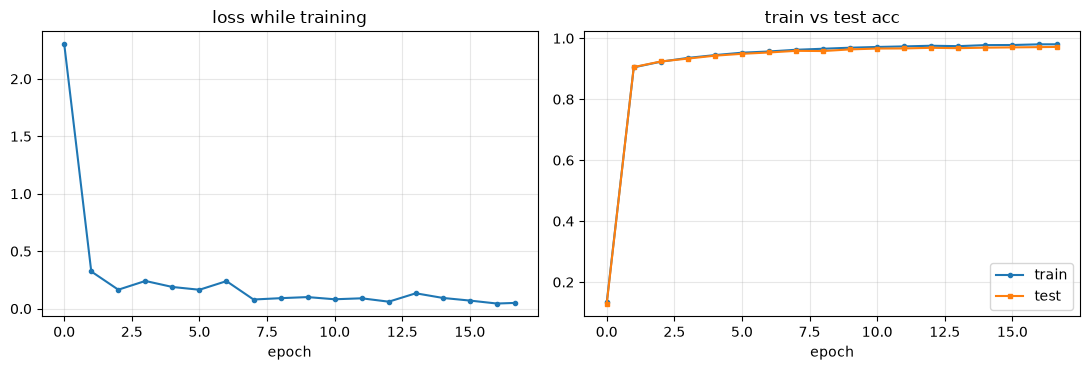

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(bp_history["epoch"], bp_history["loss"], marker="o", markersize=3)
axes[0].set_title("loss while training")
axes[0].set_xlabel("epoch")
axes[0].grid(alpha=0.3)
axes[1].plot(bp_history["epoch"], bp_history["train_acc"], marker="o", markersize=3, label="train")
axes[1].plot(bp_history["epoch"], bp_history["test_acc"], marker="s", markersize=3, label="test")
axes[1].set_title("train vs test acc")
axes[1].set_xlabel("epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

## test it

load the pickle back and run it on all 10000 test images.

In [8]:
with open(BACKPROP_MODEL, "rb") as f:
    bp_loaded = pickle.load(f)
bp_probs = bp_loaded.predict(x_test)
bp_preds = np.argmax(bp_probs, axis=1)
bp_train_acc = bp_loaded.accuracy(x_train, y_train_oh)
bp_test_acc = np.mean(bp_preds == y_test)
print(f"backprop train acuracy {bp_train_acc:.4f} ({int(bp_train_acc * len(y_train))}/{len(y_train)})")
print(f"backprop test accuracy {bp_test_acc:.4f} ({int(np.sum(bp_preds == y_test))}/{len(y_test)})")
bp_sample_df = pd.DataFrame({
    "actual": y_test[:25],
    "predicted": bp_preds[:25],
    "conf": np.round(bp_probs[np.arange(25), bp_preds[:25]], 4),
    "result": np.where(bp_preds[:25] == y_test[:25], "correct", "wrong"),
})
print("first 25 test imgs")
print(bp_sample_df.to_string())

backprop train acuracy 0.9802 (58810/60000)
backprop test accuracy 0.9716 (9716/10000)
first 25 test imgs
    actual  predicted    conf   result
0        7          7  0.9973  correct
1        2          2  0.9965  correct
2        1          1  0.9919  correct
3        0          0  0.9997  correct
4        4          4  0.9955  correct
5        1          1  0.9973  correct
6        4          4  0.9829  correct
7        9          9  0.9870  correct
8        5          5  0.9615  correct
9        9          9  0.9587  correct
10       0          0  0.9989  correct
11       6          6  0.9981  correct
12       9          9  0.9959  correct
13       0          0  0.9998  correct
14       1          1  0.9989  correct
15       5          5  0.9761  correct
16       9          9  0.9966  correct
17       7          7  0.9980  correct
18       3          3  0.9674  correct
19       4          4  0.9996  correct
20       9          9  0.9902  correct
21       6          6  0.9882  corre

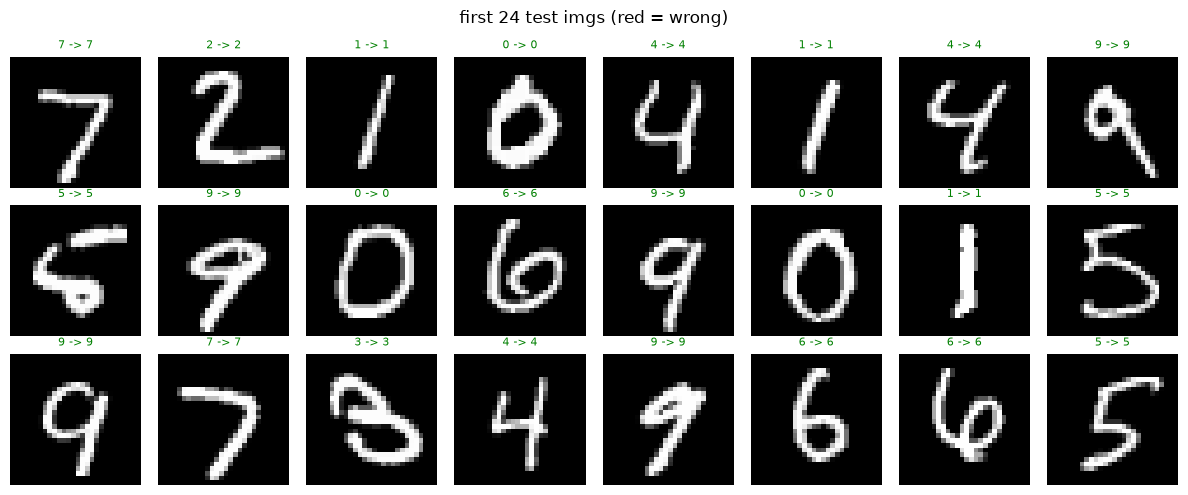

acc per digit
 digit    acc
     0 0.9898
     1 0.9833
     2 0.9729
     3 0.9812
     4 0.9745
     5 0.9585
     6 0.9760
     7 0.9523
     8 0.9723
     9 0.9534


In [9]:
# first 24, wrong ones in red
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i], cmap="gray")
    ok = bp_preds[i] == y_test[i]
    ax.set_title(f"{y_test[i]} -> {bp_preds[i]}", fontsize=8, color="green" if ok else "red")
    ax.axis("off")
fig.suptitle("first 24 test imgs (red = wrong)")
fig.tight_layout()
plt.show()
bp_per_digit = [np.mean(bp_preds[y_test == d] == d) for d in range(10)]
print("acc per digit")
print(pd.DataFrame({"digit": range(10), "acc": np.round(bp_per_digit, 4)}).to_string(index=False))

## same net in keras

same shape, 50 relu hidden units then 10 softmax. sgd with lr 0.1. mostly to see if the backprop net lands in the same ballpark.

In [10]:
class TwoLayerNetKeras:
    def __init__(self, input_size=784, hidden_size=50, output_size=10, lr=0.1):
        self.model = keras.Sequential([
            keras.Input(shape=(input_size,)),
            layers.Dense(hidden_size, activation="relu"),
            layers.Dense(output_size, activation="softmax"),
        ])
        self.model.compile(
            optimizer=keras.optimizers.SGD(learning_rate=lr),
            loss="categorical_crossentropy",
            metrics=["accuracy"],
        )
    def fit(self, x_tr, y_tr, x_va, y_va, epochs=17, batch_size=100):
        def _print_epoch(epoch, logs):
            print(f"epoch {epoch+1}  loss {logs['loss']:.4f}  acc {logs['accuracy']:.4f}  val acc {logs['val_accuracy']:.4f}")
        return self.model.fit(
            x_tr, y_tr,
            validation_data=(x_va, y_va),
            epochs=epochs,
            batch_size=batch_size,
            verbose=0,  # keras default log is noisy
            callbacks=[keras.callbacks.LambdaCallback(on_epoch_end=_print_epoch)],
        )
    def predict(self, x):
        return self.model.predict(x, batch_size=128, verbose=0)
    def evaluate(self, x, y):
        return self.model.evaluate(x, y, verbose=0)
keras_net = TwoLayerNetKeras(input_size=784, hidden_size=50, output_size=10, lr=0.1)
print("keras params", keras_net.model.count_params())  # should be 39760
start_keras = time.time()
keras_hist = keras_net.fit(x_train, y_train_oh, x_test, y_test_oh, epochs=17, batch_size=100)
keras_train_time = time.time() - start_keras
keras_net.model.save(KERAS_MODEL)
print("saved", KERAS_MODEL, f"({keras_train_time:.1f}s)")

keras params 39760


epoch 1  loss 0.4615  acc 0.8728  val acc 0.9189


epoch 2  loss 0.2598  acc 0.9263  val acc 0.9359


epoch 3  loss 0.2112  acc 0.9412  val acc 0.9471


epoch 4  loss 0.1799  acc 0.9489  val acc 0.9525


epoch 5  loss 0.1571  acc 0.9559  val acc 0.9555


... (8 outputs left out)

epoch 14  loss 0.0793  acc 0.9775  val acc 0.9707


epoch 15  loss 0.0750  acc 0.9788  val acc 0.9716


epoch 16  loss 0.0718  acc 0.9795  val acc 0.9733


epoch 17  loss 0.0686  acc 0.9804  val acc 0.9732
saved bandar_mnist_keras_model.keras (18.0s)


keras train acc 0.9826 (58957/60000)
keras test acc  0.9732 (9732/10000)


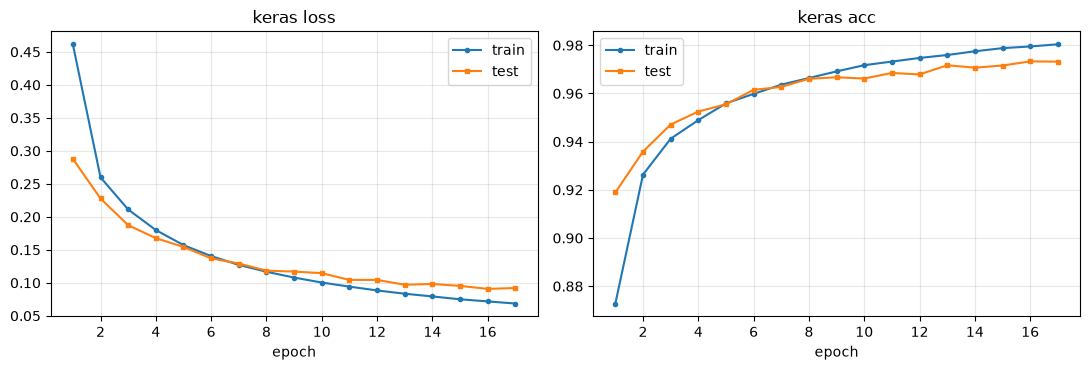

In [11]:
keras_train_loss, keras_train_acc = keras_net.evaluate(x_train, y_train_oh)
keras_test_loss, keras_test_acc = keras_net.evaluate(x_test, y_test_oh)
keras_probs = keras_net.predict(x_test)
keras_preds = np.argmax(keras_probs, axis=1)
print(f"keras train acc {keras_train_acc:.4f} ({int(round(keras_train_acc * len(y_train)))}/{len(y_train)})")
print(f"keras test acc  {keras_test_acc:.4f} ({int(np.sum(keras_preds == y_test))}/{len(y_test)})")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
epochs_range = range(1, len(keras_hist.history["loss"]) + 1)
axes[0].plot(epochs_range, keras_hist.history["loss"], marker="o", markersize=3, label="train")
axes[0].plot(epochs_range, keras_hist.history["val_loss"], marker="s", markersize=3, label="test")
axes[0].set_title("keras loss")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(epochs_range, keras_hist.history["accuracy"], marker="o", markersize=3, label="train")
axes[1].plot(epochs_range, keras_hist.history["val_accuracy"], marker="s", markersize=3, label="test")
axes[1].set_title("keras acc")
axes[1].set_xlabel("epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

## compare

three versions:
- module 6, numerical gradient, tiny hidden layer, really slow
- backprop above (numpy)
- keras, same size as the backprop net

module 6 ended at train acc 0.9128, test acc 0.9101, 1555s.

         approach     shape    how long    sec  train acc  test acc
numerical (mod 6) 784-10-10   800 steps 1555.0     0.9128    0.9101
         backprop 784-50-10 10000 steps   23.2     0.9802    0.9716
            keras 784-50-10   17 epochs   18.0     0.9826    0.9732


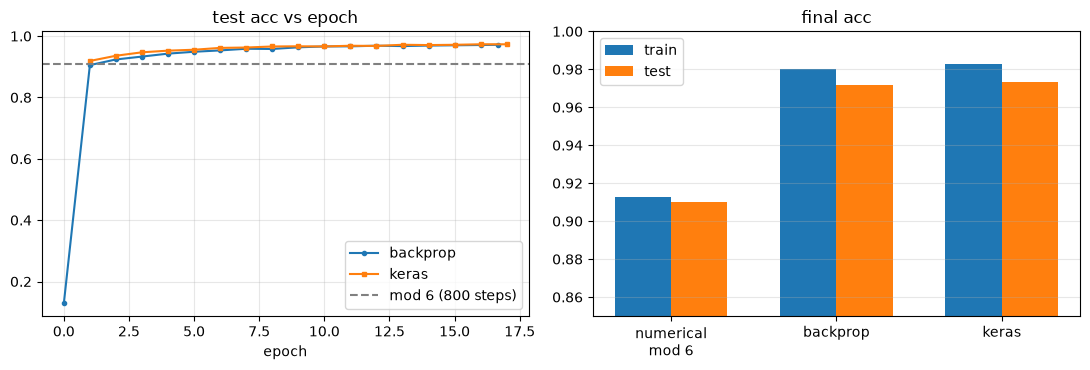

In [12]:
# module 6 final run: iter 800, train acc 0.9128, test acc 0.9101, 1555s
num_train_acc = 0.9128
num_test_acc = 0.9101
num_train_time = 1555.0
rows = [
    ["numerical (mod 6)", "784-10-10", "800 steps", round(num_train_time, 1), round(num_train_acc, 4), round(num_test_acc, 4)],
    ["backprop", "784-50-10", "10000 steps", round(bp_train_time, 1), round(float(bp_train_acc), 4), round(float(bp_test_acc), 4)],
    ["keras", "784-50-10", "17 epochs", round(keras_train_time, 1), round(float(keras_train_acc), 4), round(float(keras_test_acc), 4)],
]
comparison_df = pd.DataFrame(rows, columns=["approach", "shape", "how long", "sec", "train acc", "test acc"])
print(comparison_df.to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(bp_history["epoch"], bp_history["test_acc"], marker="o", markersize=3, label="backprop")
axes[0].plot(epochs_range, keras_hist.history["val_accuracy"], marker="s", markersize=3, label="keras")
axes[0].axhline(num_test_acc, color="gray", linestyle="--", label="mod 6 (800 steps)")
axes[0].set_title("test acc vs epoch")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)
labels = ["numerical\nmod 6", "backprop", "keras"]
train_accs = [num_train_acc, bp_train_acc, keras_train_acc]
test_accs = [num_test_acc, bp_test_acc, keras_test_acc]
x_pos = np.arange(len(labels))
axes[1].bar(x_pos - 0.17, train_accs, width=0.34, label="train")
axes[1].bar(x_pos + 0.17, test_accs, width=0.34, label="test")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels)
axes[1].set_ylim(0.85, 1.0)
axes[1].set_title("final acc")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## summary

backprop grad matched the numerical one (diff around 1e-10) and was thousands of times faster.
mnist test acc ended around 97% for both the backprop net and keras. module 6 was 91.01% and took 1555s, mostly cause of the gradient.
so the backprop net is basically learning the same thing keras does.